<a href="https://colab.research.google.com/github/busra774/dsa107-lab/blob/main/Avrupa_K%C3%B6m%C3%BCr_Santralleri__Analizi_NUTS_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install geopandas matplotlib pandas openpyxl shapely

Lütfen Global Energy Monitor (GEM) Excel dosyasını seçin:


Saving Global-Coal-Plant-Tracker-July-2026.xlsx to Global-Coal-Plant-Tracker-July-2026 (1).xlsx
Lütfen NUTS-2 sınır dosyası ZIP arşivini (NUTS_RG_01M_2021_4326.shp.zip) seçin:


Saving NUTS_RG_01M_2021_4326.shp.zip to NUTS_RG_01M_2021_4326.shp (2).zip
CSV başarıyla oluşturuldu: coal_by_nuts2_2013_2021.csv
Harita başarıyla oluşturuldu: coal_plants_europe_map.png


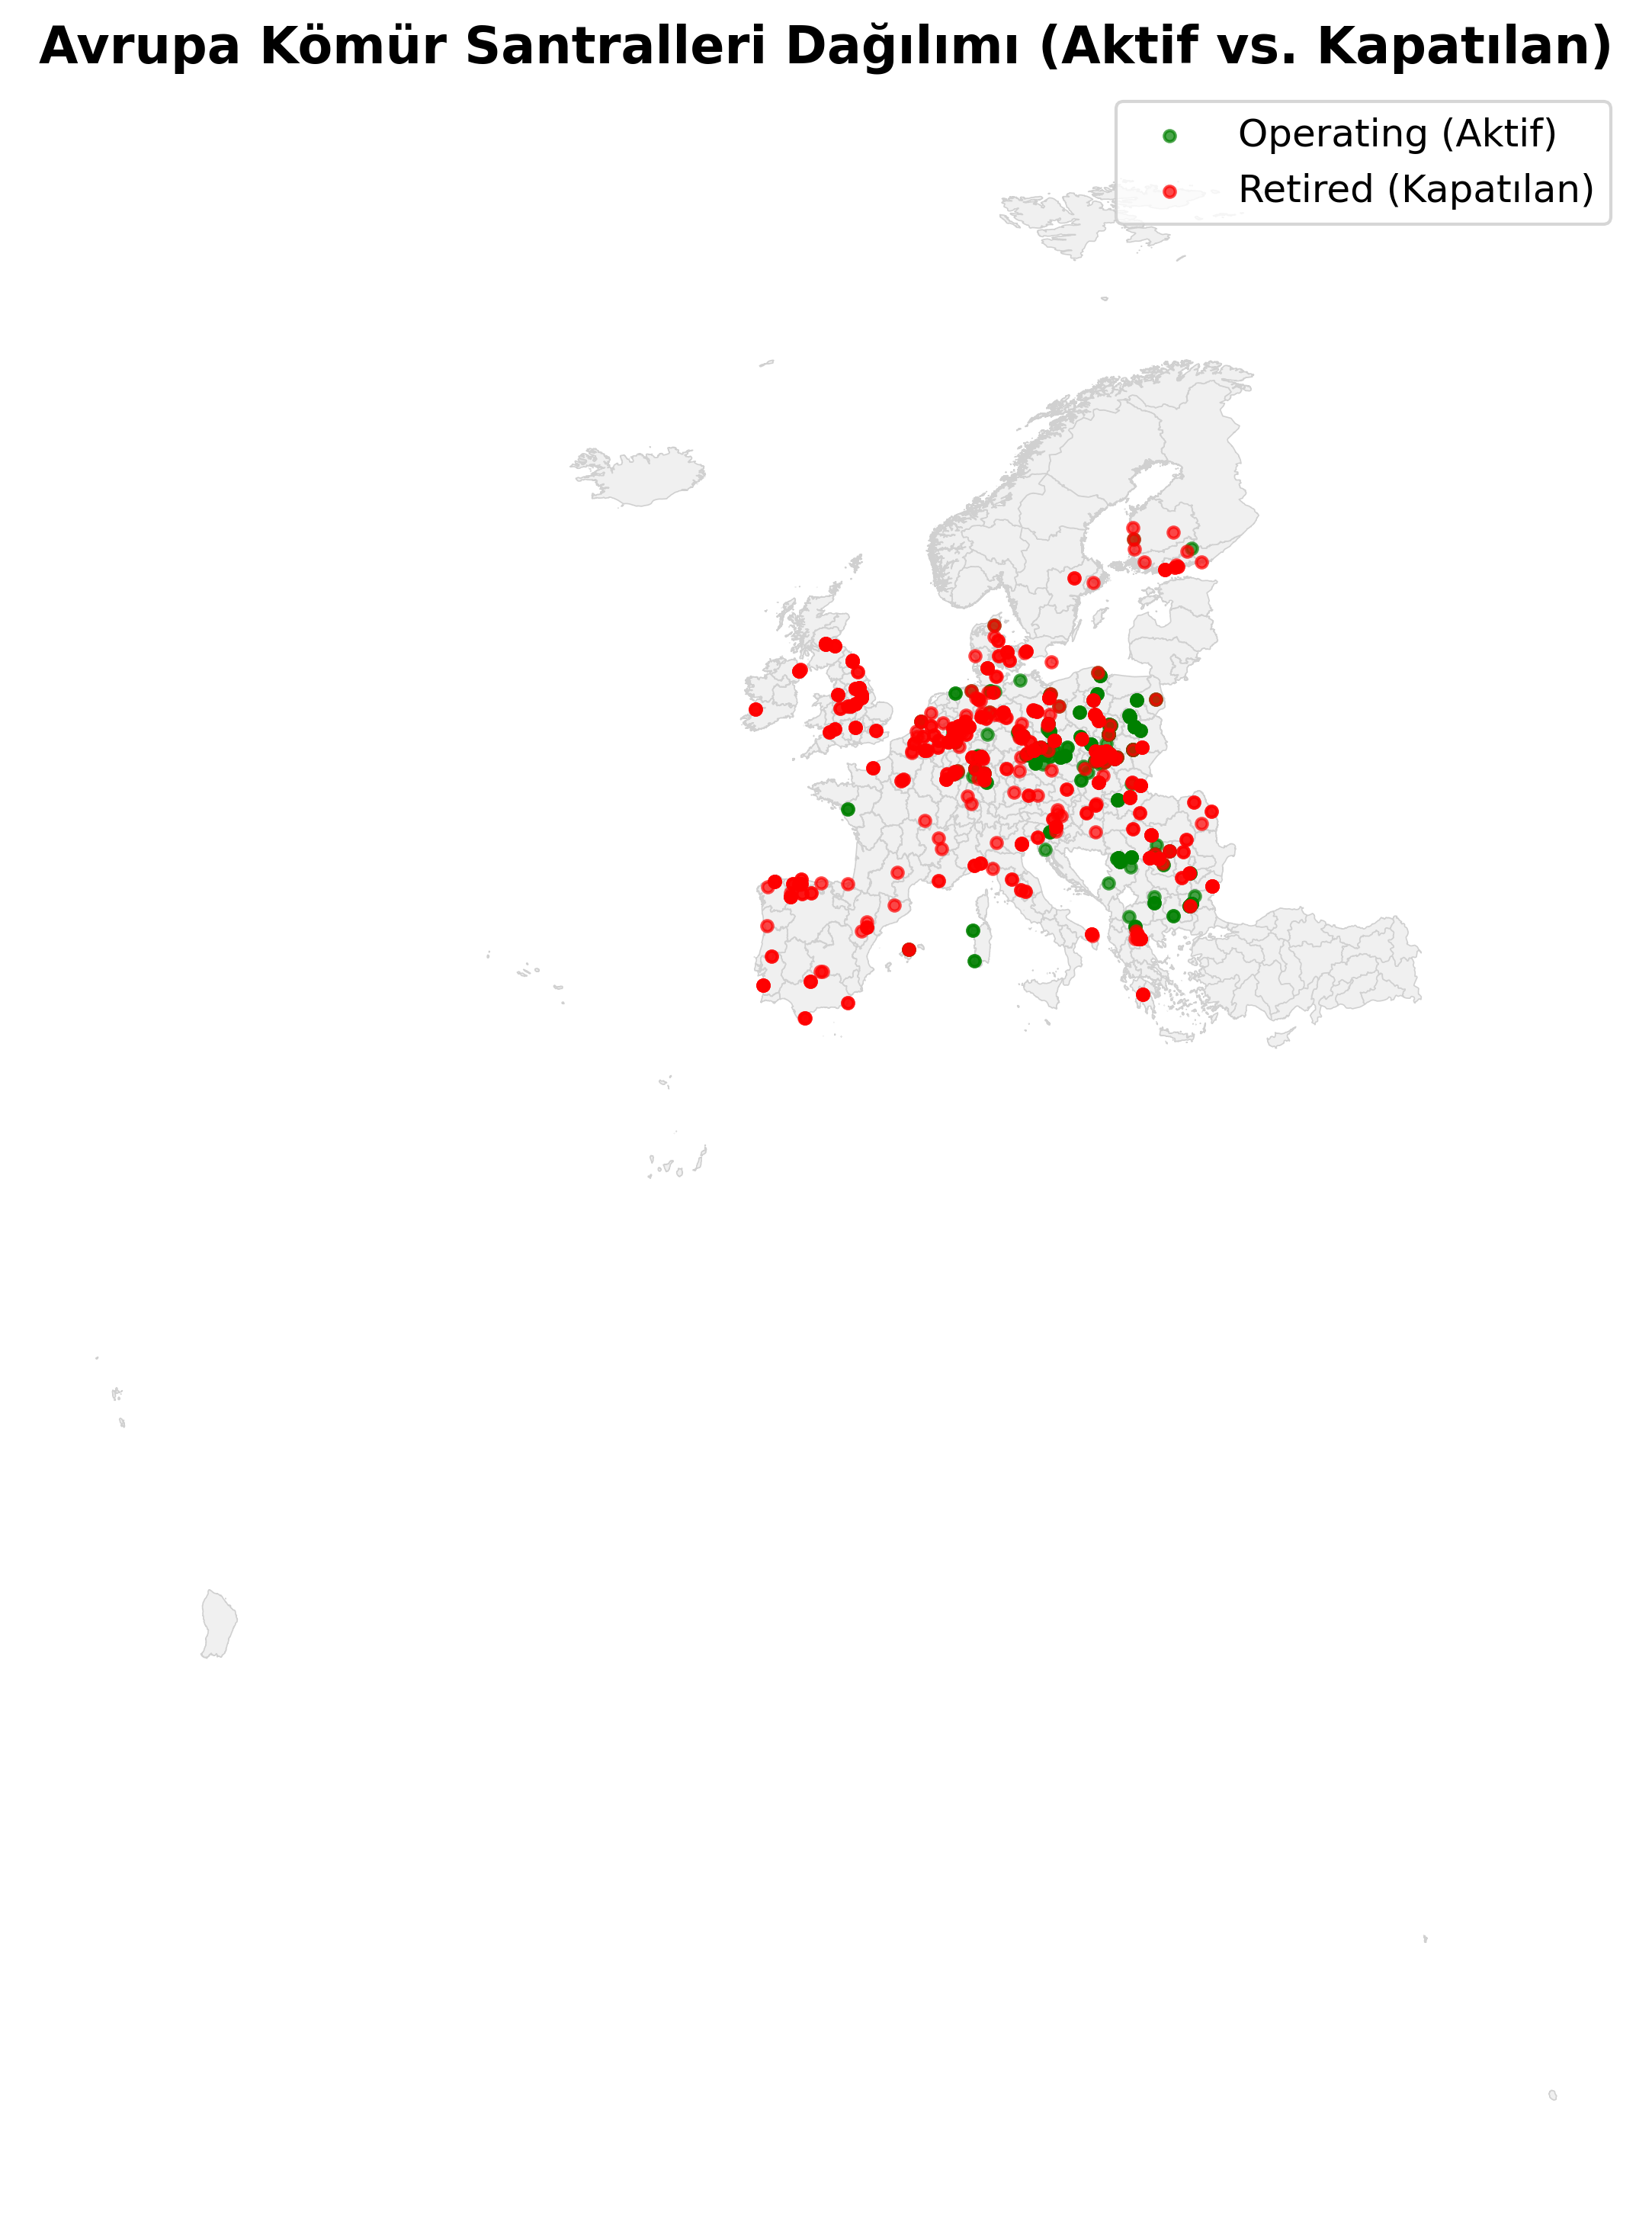

In [10]:
import zipfile
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import files
from shapely.geometry import Point

# -------------------------------------------------------------------------
# 1. DOSYALARI KOD İLE YÜKLEME (Hata almamak için en güvenli yöntem)
# -------------------------------------------------------------------------
print('Lütfen Global Energy Monitor (GEM) Excel dosyasını seçin:')
uploaded_excel = files.upload()
excel_path = list(uploaded_excel.keys())[0]

print(
    'Lütfen NUTS-2 sınır dosyası ZIP arşivini (NUTS_RG_01M_2021_4326.shp.zip)'
    ' seçin:'
)
uploaded_shp = files.upload()
zip_name = list(uploaded_shp.keys())[0]

# Zip dosyasını klasöre çıkart
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
  zip_ref.extractall('nuts_folder')

# -------------------------------------------------------------------------
# 2. GEM VERİ SETİNİ İŞLEME VE AVRUPA FİLTRELEMESİ
# -------------------------------------------------------------------------
df = pd.read_excel(excel_path, sheet_name='Units', header=0)

# Sadece Avrupa bölgesindeki santralleri filtrele
europe_df = df[df['Region'] == 'Europe'].copy()

cols_needed = [
    'Plant name',
    'Unit name',
    'Country/Area',
    'Latitude',
    'Longitude',
    'Capacity (MW)',
    'Status',
    'Retired year',
]
europe_df = europe_df[cols_needed].dropna(subset=['Latitude', 'Longitude'])

points = gpd.points_from_xy(
    europe_df['Longitude'], europe_df['Latitude'], crs='EPSG:4326'
)
plants_gdf = gpd.GeoDataFrame(europe_df, geometry=points)

# -------------------------------------------------------------------------
# 3. NUTS-2 SINIRLARINI OKUMA VE MEKÂNSAL KESİŞTİRME (Spatial Join)
# -------------------------------------------------------------------------
nuts2_shp_path = 'nuts_folder/NUTS_RG_01M_2021_4326.shp'

nuts2_gdf = gpd.read_file(nuts2_shp_path)
nuts2_gdf = nuts2_gdf[nuts2_gdf['LEVL_CODE'] == 2]  # Sadece NUTS-2 bölgeleri

if plants_gdf.crs != nuts2_gdf.crs:
  nuts2_gdf = nuts2_gdf.to_crs(plants_gdf.crs)

joined = gpd.sjoin(plants_gdf, nuts2_gdf, how='inner', predicate='within')

# -------------------------------------------------------------------------
# 4. 2013-2021 YILLARI ARASI PİVOT TABLO VE METRİK HESAPLAMA
# -------------------------------------------------------------------------
years = list(range(2013, 2022))
nuts_ids = nuts2_gdf['NUTS_ID'].unique()

grid_rows = []
for nuts_id in nuts_ids:
  for year in years:
    grid_rows.append({'NUTS_ID': nuts_id, 'Year': year})
base_grid = pd.DataFrame(grid_rows)

joined['Retired year'] = pd.to_numeric(
    joined['Retired year'], errors='coerce'
)

# Retired_MW
retired_per_year = (
    joined[joined['Status'].str.lower() == 'retired']
    .groupby(['NUTS_ID', 'Retired year'])['Capacity (MW)']
    .sum()
    .reset_index()
)
retired_per_year.rename(
    columns={'Retired year': 'Year', 'Capacity (MW)': 'Retired_MW'}, inplace=True
)

df_analysis = pd.merge(
    base_grid, retired_per_year, on=['NUTS_ID', 'Year'], how='left'
)
df_analysis['Retired_MW'] = df_analysis['Retired_MW'].fillna(0)

# Cumulative_Retired_MW
df_analysis['Cumulative_Retired_MW'] = df_analysis.groupby('NUTS_ID')[
    'Retired_MW'
].cumsum()

# Operating_MW
operating_base = joined[
    (joined['Status'].str.lower() == 'operating')
    | (joined['Retired year'] > max(years))
]
operating_per_nuts = (
    operating_base.groupby('NUTS_ID')['Capacity (MW)'].sum().reset_index()
)
operating_per_nuts.rename(
    columns={'Capacity (MW)': 'Operating_MW'}, inplace=True
)

df_analysis = pd.merge(df_analysis, operating_per_nuts, on='NUTS_ID', how='left')
df_analysis['Operating_MW'] = df_analysis['Operating_MW'].fillna(0)

final_cols = [
    'NUTS_ID',
    'Year',
    'Retired_MW',
    'Cumulative_Retired_MW',
    'Operating_MW',
]
final_df = df_analysis[final_cols]

# CSV Olarak Kaydet
final_df.to_csv('coal_by_nuts2_2013_2021.csv', index=False)
print('CSV başarıyla oluşturuldu: coal_by_nuts2_2013_2021.csv')

# -------------------------------------------------------------------------
# 5. HARİTA ÜRETİMİ VE KAYDI
# -------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 12), dpi=300)

nuts2_gdf.plot(ax=ax, color='#f0f0f0', edgecolor='#d0d0d0', linewidth=0.4)

operating_plants = joined[joined['Status'].str.lower() == 'operating']
operating_plants.plot(
    ax=ax, color='green', markersize=12, alpha=0.7, label='Operating (Aktif)'
)

retired_plants = joined[joined['Status'].str.lower() == 'retired']
retired_plants.plot(
    ax=ax, color='red', markersize=12, alpha=0.7, label='Retired (Kapatılan)'
)

plt.legend(loc='upper right', fontsize=12)
plt.title(
    'Avrupa Kömür Santralleri Dağılımı (Aktif vs. Kapatılan)',
    fontsize=16,
    fontweight='bold',
)
plt.axis('off')

plt.savefig(
    'coal_plants_europe_map.png', dpi=300, bbox_inches='tight', facecolor='white'
)
print('Harita başarıyla oluşturuldu: coal_plants_europe_map.png')
plt.show()